In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
df = pd.read_csv(r"C:\Users\delam\OneDrive\Ironhack\Labs Boot camp\lab-eda-univariate\amazon_reino_unido\amz_uk_price_prediction_dataset.csv")

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


# Parte 1

### 1. Análisis de tablas cruzadas :

Crea una tabla cruzada entre el producto categoryy el isBestSeller estado.

¿Existen categorías donde ser un superventas sea más frecuente?

Sugerencia: una opción es calcular la proporción de libros más vendidos en cada categoría y luego ordenar las categorías según esta proporción en orden descendente.

In [4]:
# Generating a crosstab for 'category' and 'isBestSeller'
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [5]:
crosstab_prop = pd.crosstab(df['category'], df['isBestSeller'], normalize='index').round(2)

crosstab_prop

isBestSeller,False,True
category,,
3D Printers,1.00,0.00
3D Printing & Scanning,1.00,0.00
Abrasive & Finishing Products,0.98,0.02
Action Cameras,1.00,0.00
Adapters,0.99,0.01
...,...,...
Wind Instruments,0.97,0.03
Window Treatments,0.98,0.02
Women,0.99,0.01


In [6]:
best_seller = crosstab_prop[True]

top_categories = best_seller.sort_values(ascending=False).round(2)

print(top_categories.head(10))

# No hay ninguna categoría donde isBestSeller sea más frecuente, si vemos, la proporción en las categorías de mayor best seller, están alrededor del 6%, lo cual muestra
# que son muy pocos los best seller en las diferentes categorías.

category
Smart Home Security & Lighting    0.06
Health & Personal Care            0.06
Grocery                           0.06
Power & Hand Tools                0.04
Mobile Phone Accessories          0.04
Wind Instruments                  0.03
Pet Supplies                      0.03
Mirrors                           0.03
Bakeware                          0.03
Billiard, Snooker & Pool          0.03
Name: True, dtype: float64


### 2. Pruebas estadísticas :

Realice una prueba de chi-cuadrado para determinar si la distribución de los productos más vendidos es independiente de la categoría del producto. 

Calcula la V de Cramér para comprender la fuerza de la asociación entre el estatus de superventas y la categoría.

In [7]:
from scipy.stats import chi2_contingency

# Chi-square test for 'category' and 'isBestSeller'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

# Con el resultado de p_value = 0, podemos ver que las variables son independientes.

(np.float64(36540.20270061387), np.float64(0.0))

In [8]:
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab_result, method="cramer")

# Con este resultado de 0.12, confirmamos que la relación entre estas dos variables es muy débil.

0.1222829439760564

### 3. Visualizaciones :

Visualice la relación entre las categorías de productos y su estatus de superventas mediante un gráfico de barras apiladas.


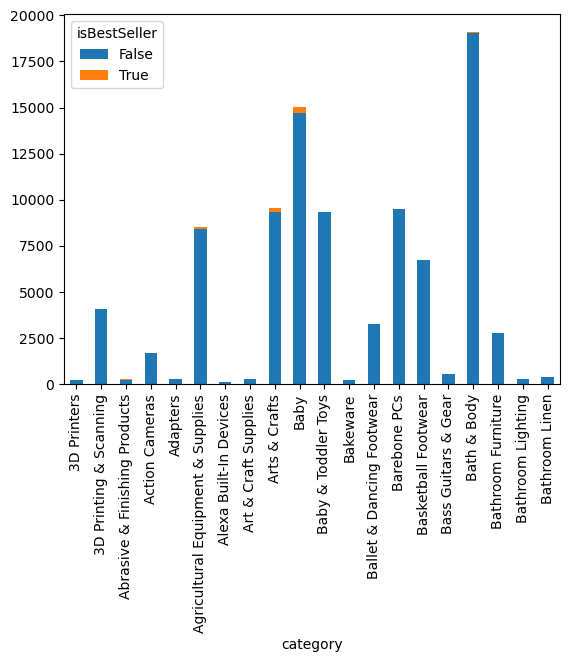

In [9]:
# Plotting a stacked bar chart for the 'crosstab_result' data
crosstab_result.head(20).plot(kind="bar", stacked=True)

plt.show()

# En este gráfico se confirma todo lo analizado antes, los best seller son una mínima proporción dentro de las ventas por categoría

# Parte 2

0. Paso preliminar: Eliminar los valores atípicos en los precios de los productos.

Para ello, podemos usar el método del rango intercuartílico (IQR). Los productos con precios inferiores al primer cuartil menos 1,5 veces el IQR o superiores al tercer cuartil más 1,5 veces el IQR se considerarán valores atípicos y se eliminarán del conjunto de datos. Los siguientes pasos se realizarán con el dataframe sin valores atípicos.

In [31]:
# calcular los cuartiles y el IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Calcular los límites en el ámbito global/actual
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_limpio = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

#  Verificar el resultado
print(f"Filas originales: {len(df)}")
print(f"Filas después de eliminar outliers: {len(df_limpio)}")

Filas originales: 2443651
Filas después de eliminar outliers: 2115963


1. Diagramas de violín :

Utilice un diagrama de violín para visualizar la distribución price entre los diferentes productos categories. Filtre las 20 categorías principales según el recuento para una mejor visualización.
¿Qué categoría de producto suele tener el precio medio más alto? No filtre aquí por categorías principales.

In [34]:
category_counts = df_limpio['category'].value_counts()

top_20_category = category_counts.head(20).index.tolist()

df_top_20 = df_limpio[df_limpio['category'].isin(top_20_category)]

top_20_category



['Sports & Outdoors',
 'Beauty',
 'Bath & Body',
 'Manicure & Pedicure Products',
 'Handmade Clothing, Shoes & Accessories',
 'Make-up',
 'Skin Care',
 'Hair Care',
 'Birthday Gifts',
 'Handmade Gifts',
 'Handmade Home Décor',
 'Luggage and travel gear',
 'Women',
 'Fragrances',
 'Handmade Kitchen & Dining',
 'Handmade Artwork',
 'Handmade Home & Kitchen Products',
 'Handmade Jewellery',
 'Men',
 'Baby']

C:\Users\delam\AppData\Local\Temp\ipykernel_10376\1029238036.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


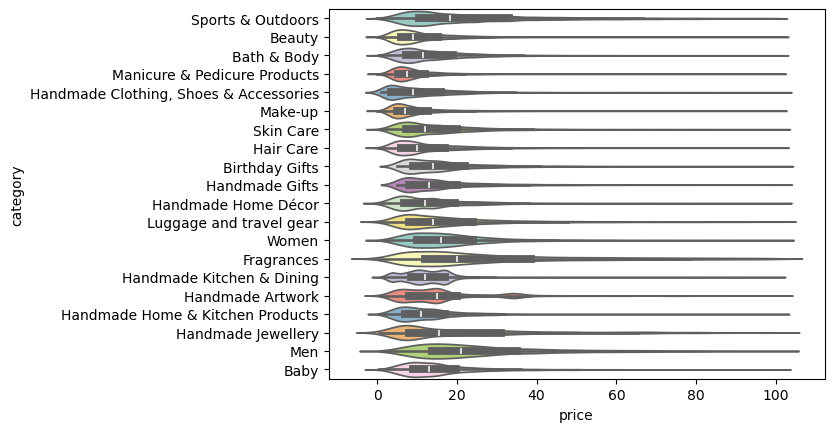

In [35]:
sns.violinplot(
    x='price',
    y='category',
    data=df_top_20,        
    palette='Set3',       
    order=top_20_category) 

plt.show()

In [36]:
precio_medio_por_categoria = df_limpio.groupby('category')['price'].mean()

cat_max_precio_medio = precio_medio_por_categoria.sort_values(ascending=False)

# 3. Mostrar el producto con el precio medio más alto y su valor
categoria_ganadora = cat_max_precio_medio.index[0]
precio_medio_ganador = cat_max_precio_medio.iloc[0]

print(f"La categoría de producto con el precio medio más alto es: '{categoria_ganadora}'")
print(f"Precio Medio: £{precio_medio_ganador:.2f}")


La categoría de producto con el precio medio más alto es: 'Motherboards'
Precio Medio: £68.77


### 2. Gráficos de barras :

Crea un gráfico de barras que compare el precio promedio de los productos de las 10 categorías de productos principales (según la cantidad).
¿Qué categoría de producto tiene el precio promedio más alto? No filtre aquí por categorías principales

C:\Users\delam\AppData\Local\Temp\ipykernel_10376\1498659349.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


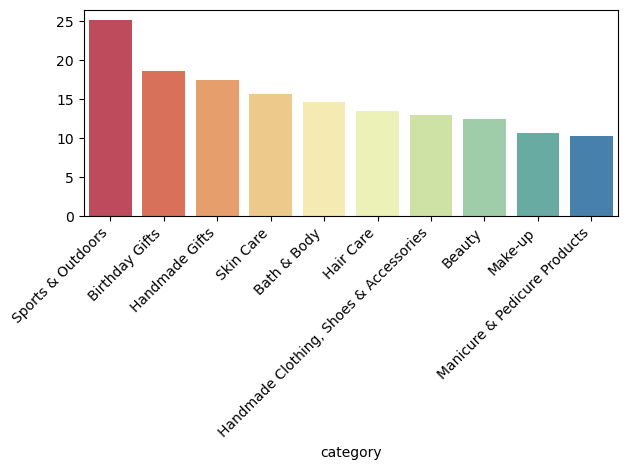

In [40]:
top_10_categories = df_limpio['category'].value_counts().head(10).index.tolist()

df_top_10 = df_limpio[df_limpio['category'].isin(top_10_categories)]

precio_medio_top_10 = df_top_10.groupby('category')['price'].mean().sort_values(ascending=False).round(2)

sns.barplot(
    x=precio_medio_top_10.index,    
    y=precio_medio_top_10.values,   
    palette='Spectral'
)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [42]:
precio_medio_global = df_limpio.groupby('category')['price'].mean()

categoria_max_precio_medio_global = precio_medio_global.sort_values(ascending=False)

categoria_ganadora = categoria_max_precio_medio_global.index[0]
precio_medio_ganador = categoria_max_precio_medio_global.iloc[0]

print(f"La categoría de producto con el precio medio más alto es: '{categoria_ganadora}'")
print(f"Precio Medio: £{precio_medio_ganador:.2f}")

La categoría de producto con el precio medio más alto es: 'Motherboards'
Precio Medio: £68.77


### 3. Diagramas de caja :

Visualice la distribución del producto ratingsmediante categorydiagramas de caja comparativos. Filtre las 10 categorías principales según el recuento para una mejor visualización.
¿Qué categoría suele recibir la valoración media más alta de los clientes? No filtre aquí por categorías principales.

C:\Users\delam\AppData\Local\Temp\ipykernel_10376\3081939103.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


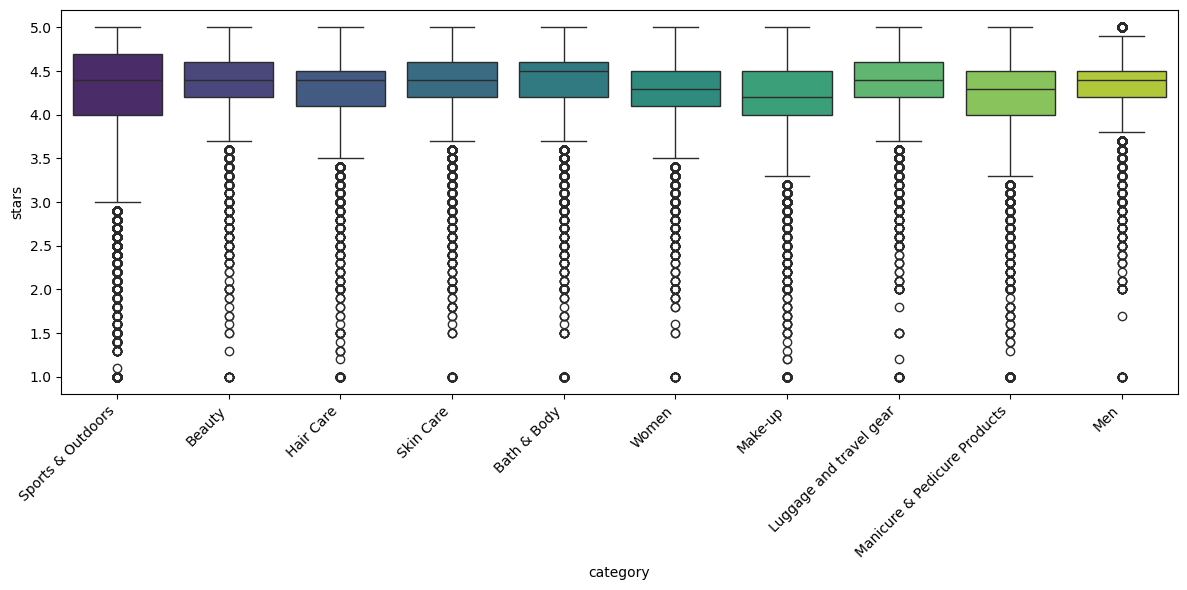

In [47]:
# Filtrar para ratings > 0
df_ratings_validos = df_limpio[df_limpio['stars'] > 0].copy()

category_counts = df_ratings_validos['category'].value_counts()
top_10_categories = category_counts.head(10).index.tolist()

df_top_10_ratings = df_ratings_validos[df_ratings_validos['category'].isin(top_10_categories)]

# 4. Crear el Box Plot
plt.figure(figsize=(12, 6))

sns.boxplot(
    x='category',
    y='stars',
    data=df_top_10_ratings, 
    palette='viridis',
    order=top_10_categories)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [52]:
valoracion_media_global = df_ratings_validos.groupby('category')['stars'].mean()

categoria_max_valoracion_media = valoracion_media_global.sort_values(ascending=False)

categoria_ganadora_rating = categoria_max_valoracion_media.index[0]
rating_medio_ganador = categoria_max_valoracion_media.iloc[0]

print(f"La categoría de producto con la valoración media más alta es: '{categoria_ganadora_rating}'")
print(f"Valoración Media: {rating_medio_ganador:.2f}")

La categoría de producto con la valoración media más alta es: 'Handmade Baby Products'
Valoración Media: 4.66


# Parte 3

1. Coeficientes de correlación :

Calcula el coeficiente de correlación entre price y stars.
¿Existe una correlación significativa entre el precio del producto y su calificación?

In [ ]:
df_ratings_validos = df_limpio[df_limpio['stars'] > 0].copy()

correlation = df_ratings_validos['stars'].corr(df_limpio['price']).round(2)
correlation

# Claramente no existe niguna correlación entre estas dos variables, y al ser prácticamente cero podemos deducir que los cambios en una variable 
# no están asociados con cambios en la otra.

np.float64(0.01)

2. Visualizaciones :

Utilice un diagrama de dispersión para visualizar la relación entre la calificación del producto y el precio. ¿Qué patrones puede observar?

Utilice un mapa de calor de correlación para visualizar las correlaciones entre todas las variables numéricas.

Analice si los precios de los productos suelen seguir una distribución normal utilizando un gráfico QQ.

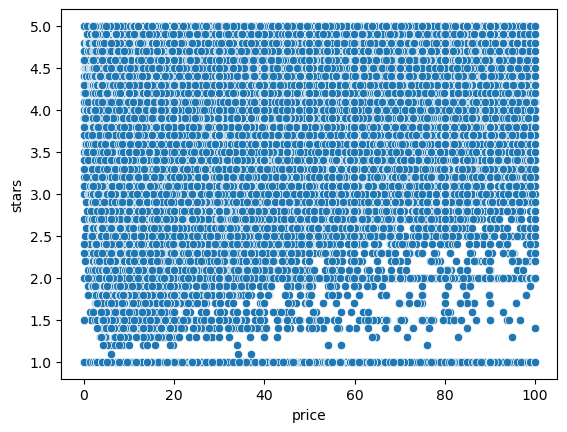

In [58]:
# Scatter plot

sns.scatterplot(data=df_ratings_validos, x='price', y='stars')

plt.show()

# Con este diagrama podemos ver que en todos los rangos de precios hay calificaciones en todos los valores.

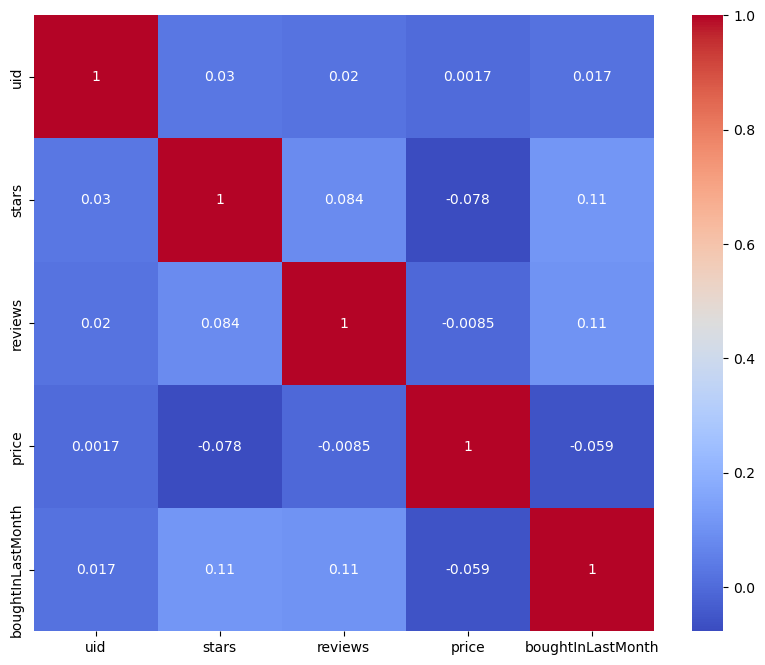

In [ ]:
df_numeric = df_limpio.select_dtypes(include=np.number)

correlation_matrix = df_numeric.corr()

# 3. Crear el Mapa de Calor
plt.figure(figsize=(10, 8))

# sns.heatmap crea el mapa de calor
sns.heatmap(
    correlation_matrix,
    annot=True,            
    cmap='coolwarm'          
)

plt.show()

# Con este mapa de calor podemos ver que la relación entre todas las variables numéricas tienen una correlación muy débil entre sí. Los cambios en una variable no se 
# relacionan con el comportamiento de otra.

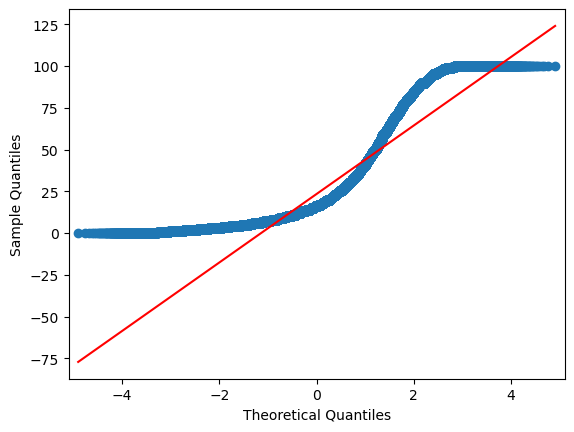

In [ ]:
# QQ Plot

import statsmodels.api as sm

sm.qqplot(df_limpio['price'], line='s');

plt.show()

# Los precios No siguen una distribución normal, se puede intuir una distribución mayoritaria de precios bajos, con un cola a la derecha de unos productos de precios altos.

